# 07 - Water Saturation

**Part A - Petrophys Curriculum**

Water saturation ($S_w$) is the fraction of the pore space occupied by formation
water. It is the single most consequential number in a petrophysical evaluation:
the hydrocarbon saturation is simply $S_h = 1 - S_w$, and everything downstream -
net pay, bulk-volume water, volumetrics - flows from it.

This lesson is the centrepiece of Part A. We build up from the classic **Archie**
equation for clean formations, then work through the four main **shaly-sand**
corrections (Simandoux, Indonesia, and the regional North Sea and Nigeria forms,
plus the lab-data Waxman-Smits / Dual-Water pair), compare them head to
head on a real shaly interval, derive Archie's $m$ and $n$ from a **Pickett plot**,
compute flushed-zone saturation $S_{xo}$, and finally show how the model choice
changes when we move from a **clastic** reservoir to a **carbonate** one.

## Learning goals

By the end of this lesson you will be able to:

- State the Archie equation and its assumptions, and know when it breaks down.
- Explain the physical idea behind each shaly-sand model and choose between them.
- Run `archie`, `simandoux`, `indonesia`, `waxman_smits`, `dual_water`,
  `calculate_sw` and `calculate_sxo` from `petrophys.interpretation.saturation`.
- Overlay the models on a real interval, read off their divergence, and reason
  about which to trust.
- Build a Pickett plot and read $m$ (and $R_w$) off the water line.
- Compute flushed-zone saturation $S_{xo}$ and understand what it tells you.
- Select an Sw model for a **carbonate** reservoir using the well's own header
  Archie parameters, and contrast it with the clastic workflow.

## Why this matters

Resistivity logs do not measure hydrocarbons - they measure how hard it is for an
electric current to pass through the rock. Water conducts; hydrocarbons and the
rock matrix do not. Archie's insight (1942) was that in a **clean, water-wet**
rock the resistivity relates to porosity and water saturation through simple power
laws:

$$ S_w^{\,n} = \frac{a\,R_w}{\phi^{m}\,R_t} $$

- $R_t$ - true (deep) formation resistivity, $\Omega\!\cdot\!m$
- $R_w$ - formation-water resistivity, $\Omega\!\cdot\!m$
- $\phi$ - porosity (effective, v/v)
- $a$ - tortuosity factor (often 1)
- $m$ - cementation exponent (~2 for clean sands)
- $n$ - saturation exponent (~2, water-wet)

The trouble: **clay** is also conductive (it holds bound water and has surface
charge). In a shaly sand Archie reads the clay conductivity as if it were extra
formation water and reports $S_w$ that is **too high** (too pessimistic). The
shaly-sand models exist to remove that clay conductivity term in different ways.

### Prerequisites

This lesson assumes you have worked through the earlier Part A lessons on data
access, clay volume (`Vcl`) and porosity. We recompute `Vcl` and effective
porosity inline here from the raw logs so the lesson runs standalone, but the
methods themselves are covered in those lessons.

In [1]:
%matplotlib inline
from petrophys.visualization import use_plot_style
use_plot_style()
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import petrophys
from petrophys.io import read_las

print('petrophys', petrophys.__version__)
print('geolink samples :', petrophys.list_samples('geolink'))
print('costa samples[:4]:', petrophys.list_samples('costa')[:4])

petrophys 3.0.0
geolink samples : ['15_9-14', '16_7-1', '25_5-1', '30_6-5']
costa samples[:4]: ['HW-10', 'HW-24', 'HW-25', 'HW-26']


## 1. Load the teaching well and rebuild the input curves

Our clastic teaching well is **30/6-5** (North Sea, depths in metres). The core
data and the Brent Group sandstone reservoir (labelled `BAAT GP.` in the bundled
tops: Ness Fm 2841-2865 m, Etive Fm 2865-2958 m) both sit around 2841-2958 m, so
we focus there. We rebuild the three inputs every saturation model needs:

1. **Vcl** - clay volume from the linear gamma-ray method.
2. **PHIE** - effective porosity from the density and neutron logs.
3. **Rt** - approximated by the deep resistivity `RDEP`. Strictly, $R_t$ is the
   resistivity of the *uninvaded* formation; the deep reading equals it only where
   invasion is shallow relative to the tool's depth of investigation. Lesson 06
   showed conductive invasion in the upper Brent sands, where deep invasion
   pulls `RDEP` toward the lower $R_{xo}$ and biases $S_w$ slightly high. Taking
   the deep reading as $R_t$ is standard practice, but it is an assumption worth
   naming.

In [2]:
from petrophys.interpretation.clay_volume import vcl_from_gr
from petrophys.interpretation.porosity import density_porosity, neutron_porosity

well = read_las(petrophys.sample('30_6-5'))
print('Well          :', well.name)
print('Depth unit    :', well.depth_unit)
print('Curves        :', well.curves)

# Reservoir interval: Brent Group (BAAT GP. in the bundled tops), cored
TOP, BASE = 2841.0, 2958.0
res = well.depth_slice(TOP, BASE)

depth = res.depth
gr    = res.get('GR').data
rhob  = res.get('RHOB').data
nphi  = res.get('NPHI').data
rt    = res.get('RDEP').data

# 1) Clay volume from GR (linear). Anchor the clean/shale lines on percentiles.
gr_clean = np.nanpercentile(gr, 5)
gr_shale = np.nanpercentile(gr, 95)
vcl = vcl_from_gr(gr, gr_clean, gr_shale)

# 2) Effective porosity: simple density-neutron average, clipped to a physical band.
phid = density_porosity(rhob, rhob_matrix=2.65, rhob_fluid=1.0)
phin = neutron_porosity(nphi)
phie = np.clip((phid + phin) / 2.0, 0.0, 0.40)

print()
print('Interval %.0f - %.0f m (%d samples)' % (TOP, BASE, res.n_samples))
print('GR clean / shale lines : %.1f / %.1f gAPI' % (gr_clean, gr_shale))
print('Vcl  mean/min/max      : %.2f / %.2f / %.2f' %
      (np.nanmean(vcl), np.nanmin(vcl), np.nanmax(vcl)))
print('PHIE mean/min/max      : %.3f / %.3f / %.3f' %
      (np.nanmean(phie), np.nanmin(phie), np.nanmax(phie)))
print('Rt   mean/min/max      : %.1f / %.1f / %.1f ohm.m' %
      (np.nanmean(rt), np.nanmin(rt), np.nanmax(rt)))

Well          : 30/6-5
Depth unit    : m
Curves        : ['LITHOLOGY_GEOLINK', 'CALI', 'DRHO', 'NPHI', 'RHOB', 'PEF', 'GR', 'DTC', 'DTE', 'RDEP', 'SP', 'RSHA', 'RMED', 'BS', 'PHIC', 'GDEN', 'KH_CORE', 'KV_CORE', 'SWC', 'SOC']

Interval 2841 - 2958 m (768 samples)
GR clean / shale lines : 26.2 / 106.5 gAPI
Vcl  mean/min/max      : 0.46 / 0.01 / 1.00
PHIE mean/min/max      : 0.211 / 0.070 / 0.400
Rt   mean/min/max      : 8.3 / 0.8 / 135.2 ohm.m


### Where is saturation before calculating it?

A LAS may contain **core saturation** (SWC) without a calculated **log
saturation** (SW). Plotting shows existing data only. The viewer converts
recognized core percentages to fractions on a display copy; it records inferred
conversions and does not alter the source curve.

That is what the two `UserWarning`s from the next cell are about: this LAS labels
`SWC` and `SOC` as fractions (`frac`), but the values are percentages, so the
viewer divides them by 100 for display and tells you it did. The viewer also
keeps that note in `raw_viewer.warnings`.

The raw-data plot therefore shows core points, not a computed continuous
saturation curve. The equations below calculate log-derived saturation under
stated assumptions. Lesson 02 demonstrates explicit core-unit overrides and
conversion provenance.

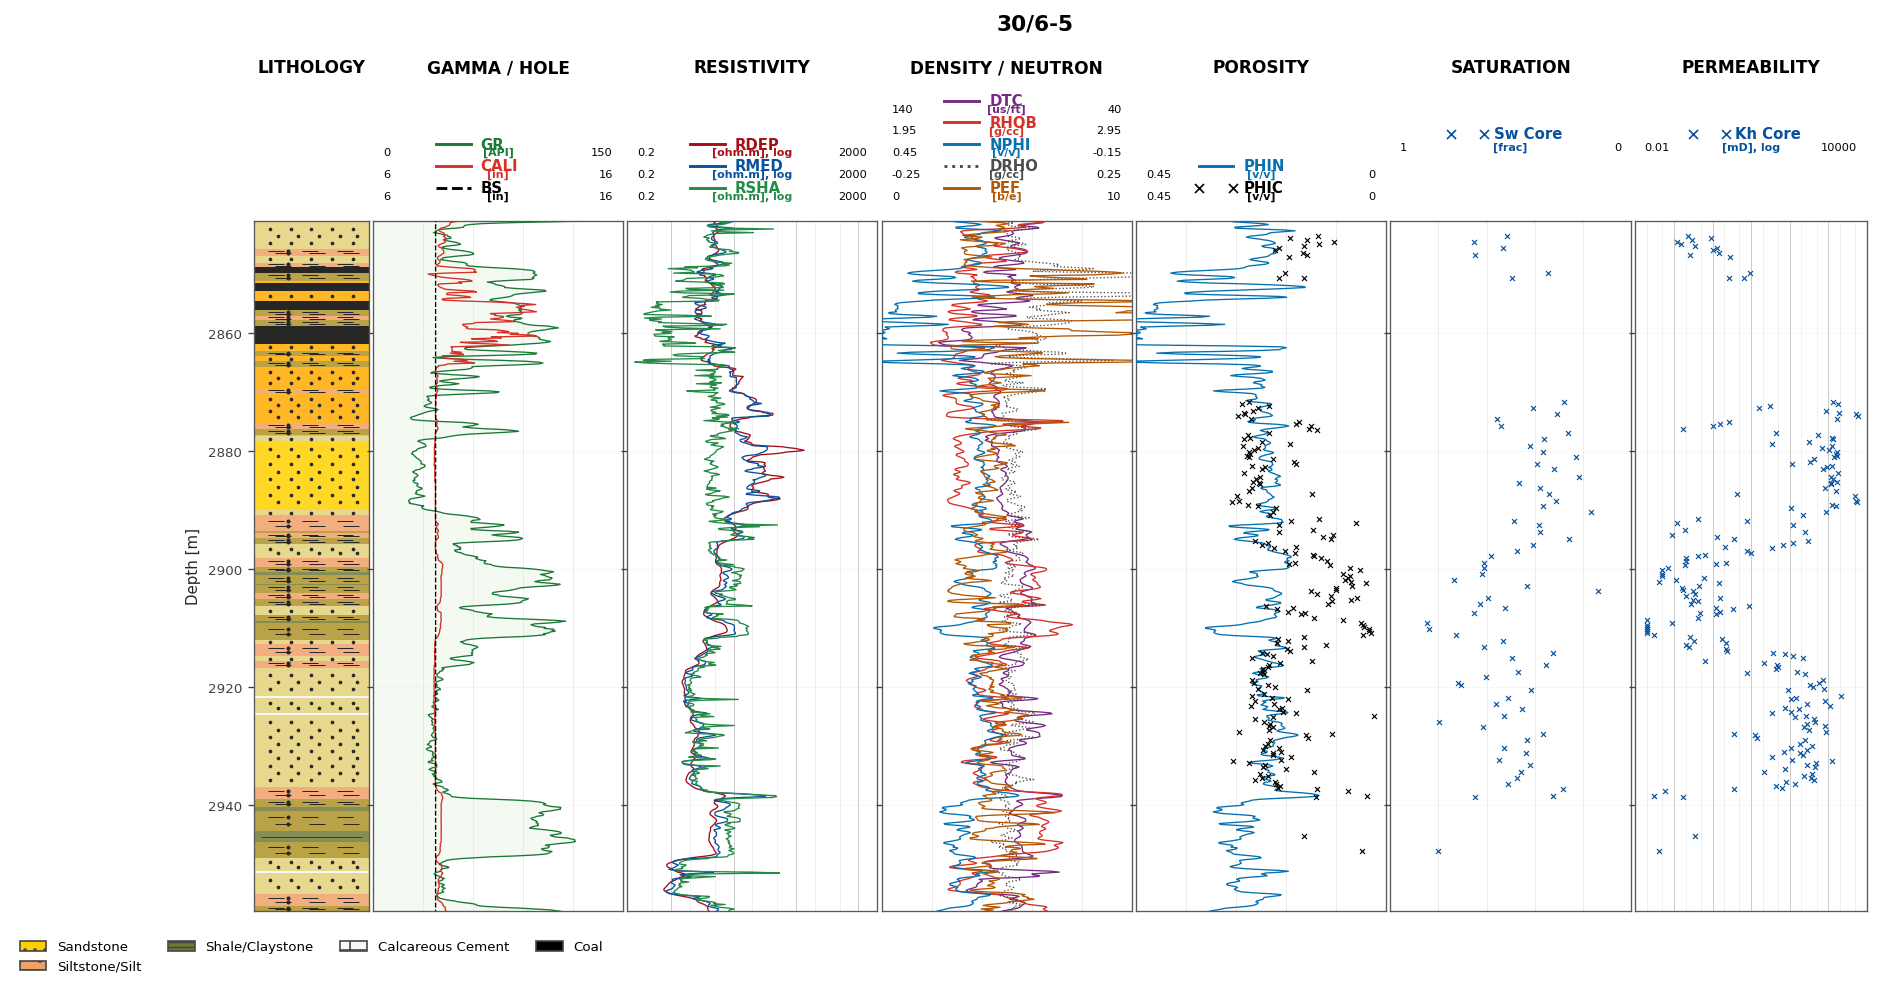

Existing log SW: False
Core display diagnostics: ["SWC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units."]


In [3]:
core_before = well["SWC"].data.copy()
raw_viewer = petrophys.plot(well, depth_range=(TOP, BASE), figsize=(14, 8))
raw_viewer.show()
raw_viewer.close()
np.testing.assert_array_equal(well["SWC"].data, core_before)
print("Existing log SW:", well.get("SW") is not None)
print("Core display diagnostics:", raw_viewer.warnings)

## 2. Archie - the clean-formation baseline

For a **clean** rock (little to no clay) Archie is all you need:

$$ S_w = \left( \frac{a\,R_w}{\phi^{m}\,R_t} \right)^{1/n} $$

The signature is `archie(rt, rw, phi, a=1.0, m=2.0, n=2.0)`. We need a value for
$R_w$ and the Archie constants. Lesson 06 showed that the LAS header's `RW` is
about ten times too high to be credible, and that independent estimates agree
with the operator's evaluation. So we use the operator's parameters (lesson 09
compares our net pay with that evaluation): $R_w = 0.070\,\Omega\!\cdot\!m$ at
230 F, the temperature the operator used for the Brent reservoir, so we apply it
unchanged over 2841-2958 m, with $a = 0.8$ and $m = n = 2$ instead of the
textbook $a = 1$. The next cell prints the values it uses.

**Assumptions baked into Archie:**

- The rock is clean (no conductive clay).
- The rock is water-wet and the pore network is well connected.
- $R_w$, $m$, $n$ are known and roughly constant over the interval.

When clay is present these assumptions fail and Archie over-estimates $S_w$.

In [4]:
from petrophys.interpretation.saturation import archie

# The LAS header carries the operator's parameter block, but it states
# RW = 0.70 ohm.m with no temperature basis - at face value that wets out the
# entire well. Lesson 06 cross-checks it against salinity and SP estimates;
# lesson 09 compares our results with the operator's evaluation, which used
# Rw = 0.070 ohm.m at 230 F with a = 0.80 and m = n = 2.
print('Header RW (as printed): %s %s, no temperature recorded'
      % (well.get_parameter('RW'), well.get_parameter('RW__UNIT')))
RW, RW_TEMP_F = 0.070, 230.0   # ohm.m at 230 F (Brent reservoir temperature)
A, M, N = 0.80, 2.0, 2.0       # operator evaluation constants
print('Rw used              : %.3f ohm.m at %.0f F' % (RW, RW_TEMP_F))
print('Archie constants     : a = %.2f, m = %.1f, n = %.1f' % (A, M, N))
print()

sw_archie = archie(rt, RW, phie, a=A, m=M, n=N)

print('Archie Sw  mean : %.3f' % np.nanmean(sw_archie))
print('Archie Sw  p10  : %.3f  (cleanest / most hydrocarbon-bearing)'
      % np.nanpercentile(sw_archie, 10))
print('Archie Sw  p90  : %.3f  (wettest)' % np.nanpercentile(sw_archie, 90))
print()
print('Hydrocarbon saturation Sh = 1 - Sw, mean : %.3f'
      % (1 - np.nanmean(sw_archie)))

Header RW (as printed): 0.7 ohmm, no temperature recorded
Rw used              : 0.070 ohm.m at 230 F
Archie constants     : a = 0.80, m = 2.0, n = 2.0

Archie Sw  mean : 0.579
Archie Sw  p10  : 0.225  (cleanest / most hydrocarbon-bearing)
Archie Sw  p90  : 0.871  (wettest)

Hydrocarbon saturation Sh = 1 - Sw, mean : 0.421


## 3. Shaly-sand models - removing the clay conductivity

Each model adds a term for the extra current the clay carries, so that only the
*free* formation water is counted. They split into two families by what they
need:

**Field-data forms** - everything comes from the logs you already have
($V_{cl}$, a shale resistivity picked off the log, and the Archie constants):

| Model | Core idea | Best when |
|-------|-----------|-----------|
| **Simandoux** | Parallel clay-conductance term $V_{cl}/R_{cl}$ | Higher salinity ($\gtrsim$ 20 kppm), dispersed clay |
| **Indonesia** (Poupon-Leveaux) | Clay and sand conductance add as square roots, weighted by $V_{cl}$ | Fresher water, laminated/dispersed clay |
| **North Sea** (regional) | Laminated-shale term $V_{sh}^{\,e}/R_{tsh}$ on the conductivity side | North Sea shaly sands - the local convention for this very well |
| **Nigeria** (Schlumberger, regional) | Fixed shale term subtracted in square-root space | Niger-delta-style laminated sands |

**Lab-data forms** - they model the clay path more physically, but need
laboratory inputs no log can give:

| Model | Extra inputs | Where the inputs come from |
|-------|--------------|----------------------------|
| **Waxman-Smits** | $\phi_t$, CEC, $B$ | CEC from core (wet chemistry) |
| **Dual-Water** | $\phi_t$, $R_{wb}$, $\phi_{cl}$ | SCAL / regional clay studies |

Without those measurements the lab-data forms run on guesses, so the working
comparison below uses the **four field-data forms**; section 3b then shows what
the lab-data pair does - and how it misbehaves - when the inputs are guessed.

### The governing equations (as implemented)

- **Archie** (the baseline all of these reduce to at $V_{cl}=0$):

$$ S_w = \left( \frac{a\,R_w}{\phi^m\,R_t} \right)^{1/n} $$

- **Simandoux**: clay adds a parallel conductance term that is *linear* in $S_w$
  (solved exactly as a quadratic for $n=2$, numerically otherwise):

$$ \frac{1}{R_t} = \frac{\phi^m}{a\,R_w}\,S_w^{\,n} + \frac{V_{cl}}{R_{cl}}\,S_w $$

- **Indonesia** (Poupon-Leveaux): clay and sand conduction paths add in
  square-root space, with $S_w^{n/2}$ as a common factor on both:

$$ \frac{1}{\sqrt{R_t}} = \left[ \frac{V_{cl}^{\,1-V_{cl}/2}}{\sqrt{R_{cl}}}
   + \frac{\phi^{m/2}}{\sqrt{a\,R_w}} \right] S_w^{\,n/2} $$

- **Waxman-Smits**: clay conductivity from the cation-exchange capacity, on
  total porosity, solved by fixed-point iteration:

$$ C_t = \frac{S_w^{\,n}}{F^{*}} \left( C_w + \frac{B\,Q_v}{S_w} \right),
   \qquad Q_v = \frac{CEC \cdot \rho_{ma}\,(1-\phi_t)}{\phi_t} $$

- **Dual-Water**: split the pore water into bound and free fractions, run Archie
  on total porosity with the mixed water, then strip the bound water back out:

$$ S_{wb} = \frac{V_{cl}\,\phi_{cl}}{\phi_t}, \qquad
   \frac{1}{R_{wt}} = \frac{S_{wb}}{R_{wb}} + \frac{1-S_{wb}}{R_w}, \qquad
   S_{wt} = \left( \frac{a\,R_{wt}}{\phi_t^m\,R_t} \right)^{1/n}, \qquad
   S_{we} = \frac{S_{wt}-S_{wb}}{1-S_{wb}} $$

The two regional variants in the comparison: the
**Nigeria (Schlumberger)** form, which subtracts a fixed shale term in
square-root space, $S_w = \big[(1/\sqrt{R_t} - V_{cl}^{\,c}/\sqrt{R_{sh}})
\big/ (\phi^{m/2}/\sqrt{a R_w})\big]^{2/n}$, and the **North Sea** laminated
form, $S_w^{\,n} = (1/R_t - V_{sh}^{\,e}/R_{tsh})\,a R_w/\phi^m$. The zoned
workflow routes to the North Sea model when `VSHE` header parameters are
present.

Below are the exact library signatures we will call.

In [5]:
from petrophys.interpretation.saturation import (
    simandoux, indonesia, north_sea_shaly_sand, nigeria_schlumberger,
)

# Estimate a clay/shale resistivity Rcl from the shaliest samples in the interval.
shale_mask = vcl > 0.6
rcl = float(np.nanmean(rt[shale_mask])) if np.any(shale_mask) else 5.0
print('Estimated Rcl (mean Rt where Vcl>0.6) : %.2f ohm.m' % rcl)
print()

# 1) Simandoux : simandoux(rt, rw, phi, vcl, rcl, a, m, n)
sw_sim = simandoux(rt, RW, phie, vcl, rcl, a=A, m=M, n=N)

# 2) Indonesia : indonesia(rt, rw, phi, vcl, rcl, a, m, n)
sw_indo = indonesia(rt, RW, phie, vcl, rcl, a=A, m=M, n=N)

# 3) North Sea laminated form: shale term Vsh^e / Rtsh on the conductivity side.
sw_ns = north_sea_shaly_sand(rt, RW, phie, vcl, rtsh=rcl, a=A, m=M, n=N)

# 4) Nigeria (Schlumberger): fixed shale term subtracted in square-root space.
sw_nig = nigeria_schlumberger(rt, RW, phie, vcl, rsh=rcl, a=A, m=M, n=N)

for name, sw in [('Archie', sw_archie), ('Simandoux', sw_sim),
                 ('Indonesia', sw_indo), ('North Sea', sw_ns),
                 ('Nigeria', sw_nig)]:
    print('%-11s Sw mean = %.3f' % (name, np.nanmean(sw)))

Estimated Rcl (mean Rt where Vcl>0.6) : 5.08 ohm.m

Archie      Sw mean = 0.579
Simandoux   Sw mean = 0.514
Indonesia   Sw mean = 0.458
North Sea   Sw mean = 0.446
Nigeria     Sw mean = 0.388


### Reading the numbers

Notice the pattern: all four shaly-sand models return **lower** $S_w$ than Archie.
That is the whole point - Archie mistook clay conductivity for water, so removing
it frees up more of the pore volume for hydrocarbons. Simandoux (0.51) is the
gentlest correction; Indonesia (0.46) and the regional North Sea form (0.45)
land close together; Nigeria (0.39) corrects hardest, because its fixed
$V_{cl}^{\,c}$ shale term subtracts the most conductivity. How far the models
spread apart tells you how clay-sensitive the interval is.

## 4. Compare the models over depth

The best way to build intuition is to overlay the $S_w$ curves against the raw
logs. On the left we plot GR, then $V_{cl}$/PHIE, then $R_t$ (log scale), and on
the right all five saturation models on a shared $S_w$ track.

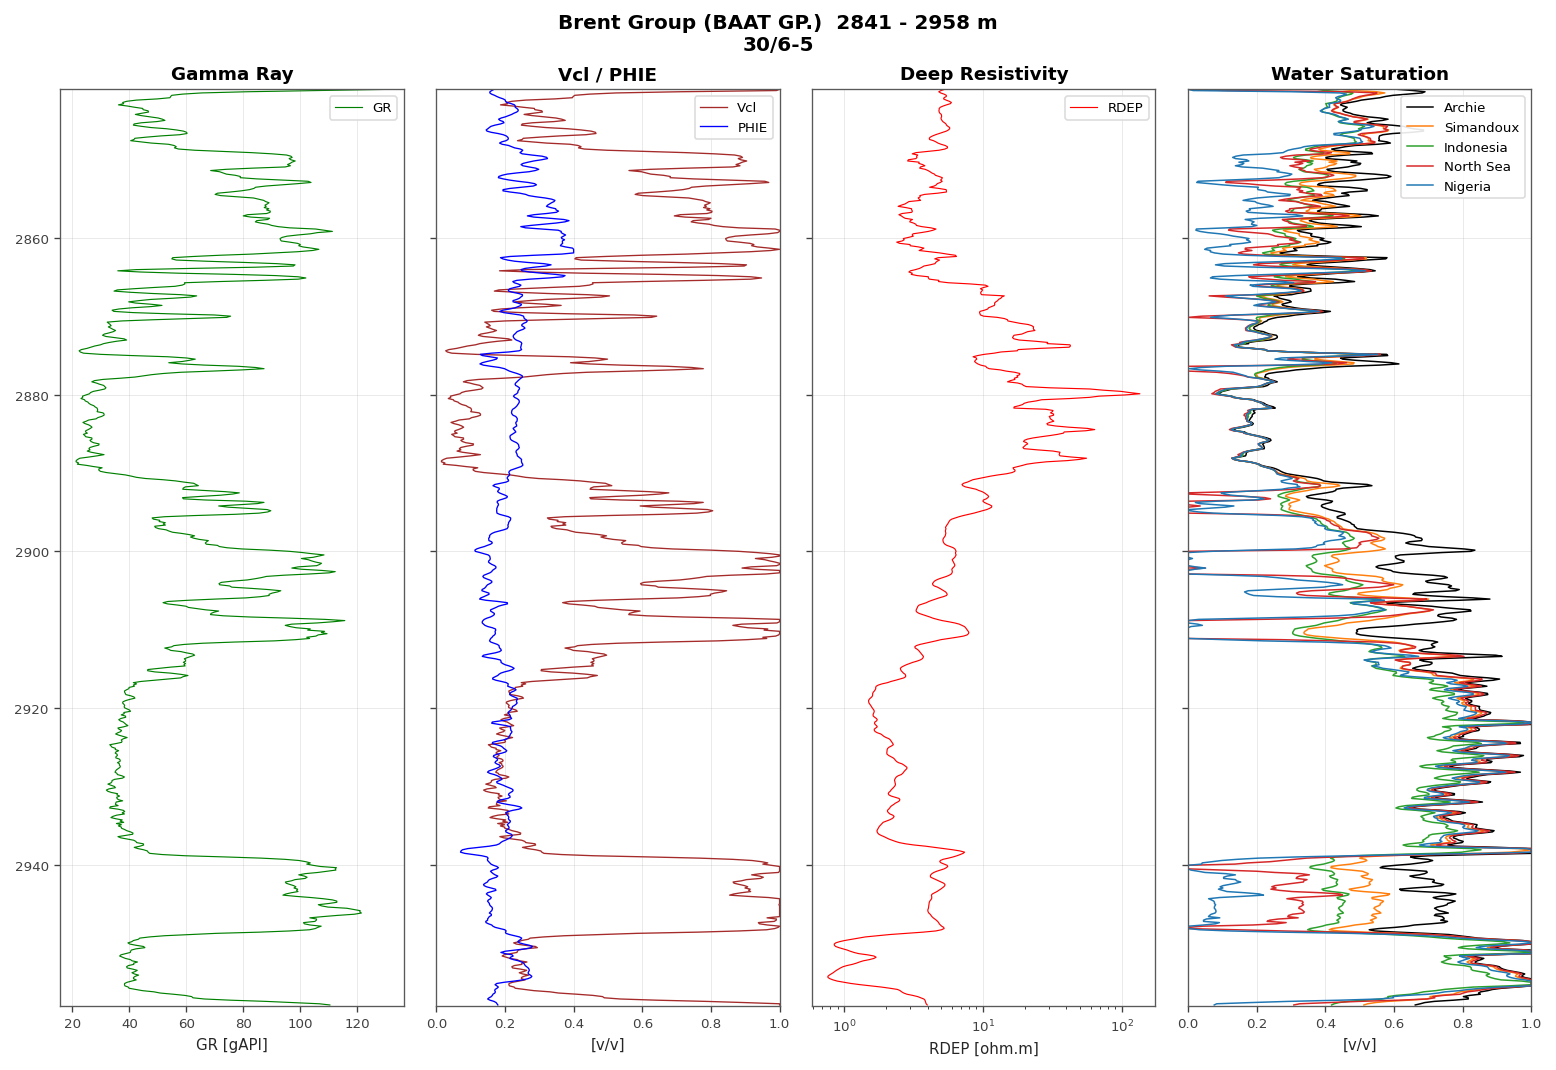

In [6]:
# Depth overlay via the library LogPlot. Attach the computed Vcl/PHIE and the
# five Sw models to the sliced reservoir well so LogPlot renders them on its grid.
from petrophys.visualization import LogPlot

res.add_curve('VCL',  vcl,  'v/v', 'Clay volume')
res.add_curve('PHIE', phie, 'v/v', 'Effective porosity')
res.add_curve('SW_ARCHIE',    sw_archie, 'v/v', 'Archie Sw')
res.add_curve('SW_SIMANDOUX', sw_sim,    'v/v', 'Simandoux Sw')
res.add_curve('SW_INDONESIA', sw_indo,   'v/v', 'Indonesia Sw')
res.add_curve('SW_NORTHSEA',  sw_ns,     'v/v', 'North Sea Sw')
res.add_curve('SW_NIGERIA',   sw_nig,    'v/v', 'Nigeria Sw')

lp = LogPlot(res, figsize=(13, 9))
lp.create_figure(n_tracks=4)

lp.add_curve(0, 'GR', color='green', linewidth=0.7)
lp.axes[0].set_title('Gamma Ray')

lp.add_curve(1, 'VCL',  color='brown', linewidth=0.8, xlim=(0, 1), label='Vcl')
lp.add_curve(1, 'PHIE', color='blue',  linewidth=0.8, xlim=(0, 1), label='PHIE')
lp.axes[1].set_title('Vcl / PHIE')

lp.add_curve(2, 'RDEP', color='red', linewidth=0.7, log_scale=True)
lp.axes[2].set_title('Deep Resistivity')

# One distinct colour per model so the five curves are distinguishable.
for name, lab, col in [('SW_ARCHIE',    'Archie',       'black'),
                       ('SW_SIMANDOUX', 'Simandoux',    'tab:orange'),
                       ('SW_INDONESIA', 'Indonesia',    'tab:green'),
                       ('SW_NORTHSEA',  'North Sea',    'tab:red'),
                       ('SW_NIGERIA',   'Nigeria',      'tab:blue')]:
    lp.add_curve(3, name, color=col, linewidth=0.9, xlim=(0, 1), label=lab)
lp.axes[3].set_title('Water Saturation')

lp.add_title('Brent Group (BAAT GP.)  %.0f - %.0f m' % (TOP, BASE))
lp.set_depth_range(TOP, BASE)
lp.show()

### A depth-zoned comparison table

Averages over the whole interval hide where the models agree and where they fight.
Let's tabulate the mean $S_w$ from each model over a **clean** sub-zone and a
**shaly** sub-zone (split on $V_{cl}$). The $V_{cl}$-driven corrections should
fade towards Archie in the clean rock and fan out in the shaly rock.

In [7]:
clean = vcl < 0.20
shaly = vcl >= 0.30

rows = []
for name, sw in [('Archie', sw_archie), ('Simandoux', sw_sim),
                 ('Indonesia', sw_indo), ('North Sea', sw_ns),
                 ('Nigeria', sw_nig)]:
    rows.append({
        'Model'          : name,
        'Sw clean (Vcl<0.2)': round(float(np.nanmean(sw[clean])), 3),
        'Sw shaly (Vcl>0.3)': round(float(np.nanmean(sw[shaly])), 3),
        'Sw all'          : round(float(np.nanmean(sw)), 3),
    })

cmp_df = pd.DataFrame(rows).set_index('Model')
# Divergence from Archie in the shaly zone (fraction of Sw)
cmp_df['delta vs Archie (shaly)'] = (
    cmp_df['Sw shaly (Vcl>0.3)'] - cmp_df.loc['Archie', 'Sw shaly (Vcl>0.3)']
).round(3)
print(cmp_df.to_string())

           Sw clean (Vcl<0.2)  Sw shaly (Vcl>0.3)  Sw all  delta vs Archie (shaly)
Model                                                                             
Archie                  0.464               0.568   0.579                    0.000
Simandoux               0.448               0.468   0.514                   -0.100
Indonesia               0.423               0.400   0.458                   -0.168
North Sea               0.451               0.342   0.446                   -0.226
Nigeria                 0.443               0.252   0.388                   -0.316


### Interpreting the divergence

- **In clean rock** (`Vcl < 0.2`) all four models collapse onto Archie:
  Simandoux (0.448), North Sea (0.451), Nigeria (0.443) and Indonesia (0.423)
  against Archie's 0.464 - their correction terms scale with $V_{cl}$ and
  vanish with the clay. That collapse is the sanity check: a shaly-sand model
  that disagrees with Archie in clean rock is mis-parameterised.
- **In shaly rock** (`Vcl > 0.3`) they fan out, and the `delta vs Archie`
  column is a direct measure of how much hydrocarbon Archie would have missed:
  from 10 saturation points (Simandoux, -0.100) through Indonesia (-0.168) and
  North Sea (-0.226) to 32 points (Nigeria, -0.316). The ordering follows how
  aggressively each shale term grows: Simandoux couples its clay term to
  $S_w$, the North Sea form subtracts a full $V_{sh}^{1.6}/R_{tsh}$
  conductance up front, and Nigeria subtracts a similar term in square-root
  space, where it bites hardest.
- The **spread between the models** is your uncertainty band. When they
  disagree strongly you are sensitive to $R_{cl}$ and the shale exponent - the
  parameters you know least well - and should calibrate against core or SCAL.

**Rule of thumb for picking a model** (this is the logic `SaturationModule`
automates): clean rock -> Archie; shaly clastic with saline water -> Simandoux;
fresher water -> Indonesia; a North Sea well with laminated shale (or
`VSHE`-style header parameters, which the zoned workflow routes on
automatically) -> the regional North Sea form; CEC measured in the lab ->
Waxman-Smits (the router only selects it when you actually supply `cec`);
SCAL-derived $R_{wb}$ and clay porosity -> Dual-Water. The lab-data pair is
demonstrated next - including what goes wrong when their inputs are guessed.

### 3b. The lab-data family: Waxman-Smits and Dual-Water

The library also implements the two lab-calibrated models (`waxman_smits`,
`dual_water`). They are the right tools **when the laboratory inputs exist**:
CEC from core wet-chemistry for Waxman-Smits; bound-water resistivity and clay
porosity from SCAL or a regional clay study for Dual-Water. 30/6-5 has none of
that, so below we run them on explicitly-guessed inputs purely to show the API
and the failure mode - and the `SaturationModule` router behaves the same way:
it only ever selects Waxman-Smits when you actually supply `cec`; it does not
guess.

In [8]:
from petrophys.interpretation.saturation import waxman_smits, dual_water
from petrophys.interpretation.porosity import total_porosity

# Total porosity for the total-porosity models (lesson 04's adaptive blend).
phit = total_porosity(nphi, phid, method='adaptive')

# GUESSED lab inputs - illustration only, flagged:
CEC, RHO_MA, B_COEFF, M_STAR = 0.10, 2.65, 4.0, 2.0   # CEC in meq/g
RWB, PHI_CL = 0.3 * RW, 0.15                           # Rwb ~ 0.3*Rw first guess

sw_ws = waxman_smits(phie, rt, RW, CEC, RHO_MA, B_COEFF, m_star=M_STAR, n=N)
sw_dw = dual_water(phit, rt, RW, RWB, vcl, PHI_CL, a=A, m=M, n=N)

clean, shaly = vcl < 0.20, vcl >= 0.30
for name, sw in [('Waxman-Smits', sw_ws), ('Dual-Water', sw_dw)]:
    print('%-13s Sw mean = %.3f | clean %.3f | shaly %.3f'
          % (name, np.nanmean(sw), np.nanmean(sw[clean]), np.nanmean(sw[shaly])))


Waxman-Smits  Sw mean = 0.518 | clean 0.407 | shaly 0.496
Dual-Water    Sw mean = 0.250 | clean 0.386 | shaly 0.062


#### Parameter-consistency warning

Near-zero Dual-Water saturation in the shaly samples is not a hydrocarbon show.
With the guessed inputs, calculated clay-bound water rivals the total water
supported by resistivity. The result exposes an inconsistent parameter set and
shows why CEC, clay porosity, and bound-water properties should come from lab or
field calibration.


## 5. The high-level driver: `calculate_sw`

You rarely wire up the models by hand. `calculate_sw(well, rw, a, m, n, model=...)`
reads the curves off the well and routes automatically (`model='auto'`) or forces
a single model. With `'auto'` it decides **sample by sample** using $V_{cl}$,
lithology and salinity, so one well can legitimately use several models across
depth. Here we run it in forced modes to reproduce our by-hand numbers, then in
auto mode.

In [9]:
from petrophys.interpretation.saturation import calculate_sw

# Force Archie on the whole well, using our Rw. The driver reads RDEP and a
# porosity curve (PHIE_CC/PHIE) off the well; 30/6-5 has neither a VCL nor a
# PHIE curve stored, so we add PHIE to the sliced well for the demo.
res_demo = well.depth_slice(TOP, BASE)
res_demo.add_curve('PHIE', phie, 'v/v', 'Effective porosity (demo)')
res_demo.add_curve('VCL',  vcl,  'v/v', 'Clay volume (demo)')

sw_auto     = calculate_sw(res_demo, rw=RW, a=A, m=M, n=N, model='auto',
                           salinity=30000.0)
sw_forced_a = calculate_sw(res_demo, rw=RW, a=A, m=M, n=N, model='archie')

print('calculate_sw (forced archie) mean : %.3f' % np.nanmean(sw_forced_a))
print('calculate_sw (auto route)    mean : %.3f' % np.nanmean(sw_auto))
print()
print('For reference, our by-hand Archie mean : %.3f' % np.nanmean(sw_archie))

calculate_sw (forced archie) mean : 0.579
calculate_sw (auto route)    mean : 0.522

For reference, our by-hand Archie mean : 0.579


## 6. The Pickett plot - deriving $m$ (and $R_w$)

The Pickett plot is a log-log crossplot of **porosity (x) vs $R_t$ (y)**. Taking
logs of Archie for a **100% water** rock ($S_w=1$):

$$ \log R_t = -m\,\log\phi + \log(a\,R_w) $$

So on log-log axes the water-bearing points fall on a straight line whose
**slope is $-m$** and whose position fixes $a\,R_w$. Points that plot above that
water line are hydrocarbon-bearing (higher $R_t$ at the same porosity).
`pickett_analysis(rt, phi, vcl=..., vcl_cutoff=...)` fits a least-squares
regression through the clean points and returns an `ArchieParameters` object
plus a stats dict - a useful first look, but note the trap: a regression runs
through the *middle* of the cloud, so half the points end up below "$S_w=1$",
which is impossible. The industry pick is the **lower envelope**: fix $m$ at a
plausible cementation exponent and slide the line down until the wet points sit
on it; $R_w$ then comes from the envelope (here a low percentile of
$R_t\,\phi^m/a$), not from the mean.

**We need a water leg for a good fit.** The Brent reservoir above carries
hydrocarbon over much of its thickness, so many of its points sit *above* the
water line and would give a meaningless slope. Instead we use the deeper, low-resistivity
**Statfjord Fm sandstone (3223-3556 m)**, which is largely water-bearing - its
points define a clean $S_w=1$ line.

**Why not select only the water-saturated points?** Because that is circular:
deciding which points have $S_w=1$ requires the very $R_w$ the plot is trying
to find. The practical resolution has two layers. First, choose the wettest
*interval* you have (here the Statfjord; in a real study you would confirm a
genuine aquifer with pressure gradients from RFT/MDT or regional knowledge -
this well has no certified aquifer, and even the Statfjord has a few tight,
resistive streaks). Second, let the envelope do the point selection
statistically: the lowest-$R_t$ edge of the clean cloud *is* the
water-saturated subset, self-selected without ever computing $S_w$.

In [10]:
from petrophys.interpretation.electrical.cementation import pickett_analysis

# Load a water-bearing clean sand for the Pickett fit.
stat = well.depth_slice(3223.0, 3556.0)
gr_s   = stat.get('GR').data
rhob_s = stat.get('RHOB').data
nphi_s = stat.get('NPHI').data
rt_s   = stat.get('RDEP').data

vcl_s  = vcl_from_gr(gr_s, np.nanpercentile(gr_s, 5), np.nanpercentile(gr_s, 95))
phie_s = np.clip(
    (density_porosity(rhob_s) + neutron_porosity(nphi_s)) / 2.0, 0.0, 0.40)

# Fit the water line: regress log(Rt) on log(phi) over clean (Vcl<0.3) points.
params, stats = pickett_analysis(rt_s, phie_s, vcl=vcl_s, vcl_cutoff=0.3)
print('Derived cementation exponent m : %.2f' % params.m)
print('Fit R^2                        : %.3f' % stats['r_squared'])
print('N points used                  : %d'   % stats['n_points'])
print('Intercept log10(a*Rw)          : %.3f' % stats['intercept'])

# Recover an apparent a*Rw from the intercept: intercept = log10(a*Rw)
rw_apparent = 10 ** stats['intercept']
print('Apparent a*Rw from intercept   : %.3f ohm.m' % rw_apparent)

# The regression above runs THROUGH the clean cloud, so about half the points
# would plot below "Sw = 1" - physically impossible. The industry pick is
# different: fix m at a plausible cementation exponent and slide the water
# line down to the LOWER ENVELOPE of the clean cloud, so wet points sit ON it
# and everything else sits above. Rw then comes from the envelope, not the mean.
M_PICK = 2.0
env = np.isfinite(rt_s) & np.isfinite(phie_s) & (vcl_s < 0.3) & (phie_s > 0.05)
rw_env = float(np.nanpercentile(rt_s[env] * phie_s[env] ** M_PICK, 5)) / A
print()
print('Envelope water-line pick : m = %.1f (assumed), Rw = %.4f ohm.m' % (M_PICK, rw_env))

# How do the two picks compare with the operator's Rw used above?
print()
print('envelope Rw / operator Rw         : %.2f' % (rw_env / RW))
print('regression a*Rw / operator a*Rw   : %.1f' % (rw_apparent / (A * RW)))

Derived cementation exponent m : 1.15
Fit R^2                        : 0.849
N points used                  : 469
Intercept log10(a*Rw)          : -0.415
Apparent a*Rw from intercept   : 0.384 ohm.m

Envelope water-line pick : m = 2.0 (assumed), Rw = 0.0582 ohm.m

envelope Rw / operator Rw         : 0.83
regression a*Rw / operator a*Rw   : 6.9


#### Regression line versus water-line envelope

The regression passes through the clean-sand cloud and is not the water line.
The envelope method fixes a plausible cementation exponent and moves the line
to the lower edge of the cloud, where wet samples lie on $S_w = 1$ and the
remaining samples plot above it.


We visualise it with the library plotter using the **envelope pick** (fixed
$m=2.0$, $R_w$ from the low-$R_t$ edge), which makes the geometry explicit:
the $S_w=1$ water line hugs the base of the clean cloud, the parallel
iso-$S_w$ lines sit above it, and the sparse low-porosity, high-resistivity
points in the upper left land at $S_w \approx$ 20-60% - thin tight streaks, not
a missed discovery (the NPD records no Statfjord discovery in this well). Those
are exactly the points a regression would wrongly pull the line toward; the
envelope ignores them, which is the point. Points are coloured by
resistivity so that cluster is easy to spot.

The iso-$S_w$ lines are not decoration - they are Archie itself, drawn at
fixed saturations. Solving Archie for $R_t$ at a given $S_w$:

$$ R_t(\phi; S_w) = \frac{a\,R_w}{\phi^m \, S_w^{n}} $$

so on log-log axes every line has the same slope $-m$, and the $S_w<1$ lines
are the water line shifted UP by $n\,\log_{10}(1/S_w)$ decades (with
$n=2$: the 80% line sits 0.19 decades above the water line, 60% at 0.44,
40% at 0.80, 20% at 1.40). Once $R_w$ and $m$ are picked, the whole family
is determined - reading a point's $S_w$ off the plot is solving Archie
graphically.

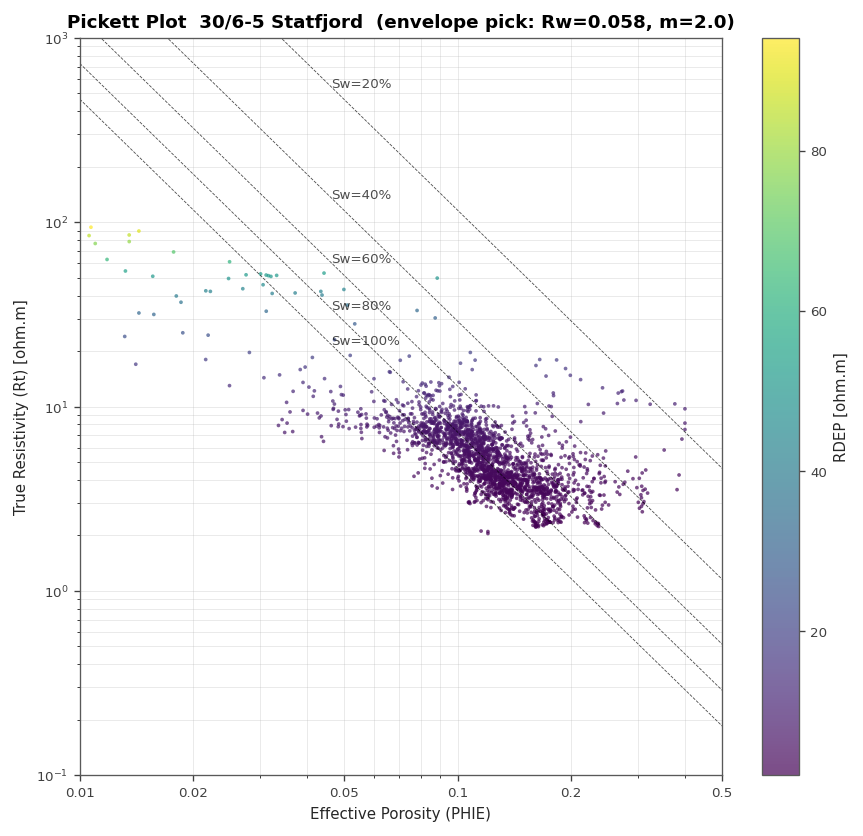

In [11]:
# Pickett plot via the library plotter. Attach PHIE to the water-bearing
# Statfjord slice (RDEP is already present) and let create_pickett_plot draw the
# log-log crossplot with Archie iso-Sw lines using the envelope pick.
from petrophys.visualization import create_pickett_plot

stat.add_curve('PHIE', phie_s, 'v/v', 'Effective porosity (Statfjord)')

pickett = create_pickett_plot(stat, rw=rw_env, phie_curve='PHIE',
                              rt_curve='RDEP', color_curve='RDEP',
                              a=A, m=M_PICK, n=N, figsize=(7.5, 7))
pickett.ax.set_title('Pickett Plot  30/6-5 Statfjord  (envelope pick: Rw=%.3f, m=%.1f)'
                     % (rw_env, M_PICK))
pickett.show()

#### Pickett-plot check

The $S_w = 1$ line follows the lower edge of the cloud. Wet points sit on the
line and the remaining points plot above it, avoiding physically impossible
sub-unity water-line points.


**How to use the derived numbers:** the two methods disagree for a reason.
The regression returned a low $m$ and an $a\,R_w$ several times the operator's
(both printed above) - artifacts of fitting through a mixed cloud (scatter, thin
tight streaks, residual hydrocarbon points all flatten the slope and lift the
intercept). The envelope pick with a fixed, plausible $m=2.0$ lands within about
a fifth of the 0.070 ohm.m operator value we applied to the Brent interval (the
printed ratio) - good agreement, and in the right direction: the Statfjord is
deeper and hotter than the Brent sands, so its in-situ $R_w$ should sit somewhat
below a value quoted at 230 F. The general guidance stands: sanity-check any
Pickett $m$ against expected ranges (~1.8-2.0 for clean, well-connected sands;
2.2-2.8 for vuggy/moldic carbonates) and against core-measured $m$; treat the
intercept as a consistency check on $R_w$, and prefer the envelope over a
regression whenever the "water leg" may carry hydrocarbon-bearing points - as
the sparse tight streaks here do.

## 7. Flushed-zone saturation $S_{xo}$

Drilling mud filtrate invades the near-wellbore rock and flushes out moveable
hydrocarbon. The **flushed zone** therefore has its own water saturation $S_{xo}$,
computed with Archie but using the *shallow* resistivity $R_{xo}$ and the mud
filtrate resistivity $R_{mf}$:

$$ S_{xo}^{\,n} = \frac{a\,R_{mf}}{\phi^{m}\,R_{xo}} $$

`calculate_sxo(rxo, rmf, phi, a, m, n)` is Archie under the hood. Because
invasion sweeps moveable oil away, $S_{xo} \ge S_w$; the gap
$S_{xo}-S_w$ is a moveability indicator (more on that in lesson 09). 30/6-5 has a
shallow curve `RSHA`, so we can compute a real $S_{xo}$.

We take $R_{mf}$ from the LAS header (0.08 ohm.m) and use it as the in-situ
value. The header records no temperature for it, and lesson 06 shows that the
filtrate chloride points to a somewhat lower $R_{mf}$ at reservoir temperature,
which would lower $S_{xo}$ a little. Treat $S_{xo}$ here as approximate.

In [12]:
from petrophys.interpretation.saturation import calculate_sxo

rxo = res.get('RSHA').data     # shallow (flushed-zone) resistivity
RMF = float(well.get_parameter('RMF'))   # 0.08 ohm.m from the header; no temperature recorded

sxo = calculate_sxo(rxo, RMF, phie, a=A, m=M, n=N)

# Reference Sw: use Archie, which shares the same a/m/n/porosity chain as
# calculate_sxo, so the Sxo-Sw gap reflects invasion rather than model choice.
print('Sxo   mean : %.3f' % np.nanmean(sxo))
print('Sw    mean : %.3f  (Archie)' % np.nanmean(sw_archie))
moveable = np.clip(sxo - sw_archie, 0, 1)
print('Sxo - Sw   : %.3f  (moveable-hydrocarbon indicator, mean)'
      % np.nanmean(moveable))


Sxo   mean : 0.627
Sw    mean : 0.579  (Archie)
Sxo - Sw   : 0.111  (moveable-hydrocarbon indicator, mean)


#### Moveable-hydrocarbon interpretation

A positive $S_{xo} - S_w$ indicates that mud filtrate displaced hydrocarbon
from the flushed zone. It is therefore evidence that at least part of the
hydrocarbon volume was moveable.


## 8. Carbonate model selection - Archie on a Costa well (HW-3)

Everything so far was a **clastic** North Sea sand. Carbonates behave differently:
they are usually **clean** (low $V_{cl}$), so the shaly-sand corrections are often
unnecessary - but their complex pore systems mean $m$ and $n$ drift away from 2 and
must be measured. The `petrophys` sample set includes a carbonate field ("Costa",
depths in feet); each Costa LAS file covers only the Kharaib-2 reservoir
interval, not the whole well. Well **HW-3** even carries its Archie parameters in
the LAS header, which we read with `well.get_parameter(...)`.

In [13]:
hw3 = read_las(petrophys.sample('HW-3'))
print('Well       :', hw3.name)
print('Depth unit :', hw3.depth_unit)
print('Curves     :', hw3.curves)
print()

# Read the Archie parameters straight from the header - do NOT assume 2.0.
rw_hw3 = hw3.get_parameter('RW')
a_hw3  = hw3.get_parameter('A')
m_hw3  = hw3.get_parameter('M')
n_hw3  = hw3.get_parameter('N')
print('Header Archie params : Rw=%.4f  a=%.2f  m=%.2f  n=%.2f'
      % (rw_hw3, a_hw3, m_hw3, n_hw3))

rt_hw3   = hw3.get('RT').data
phie_hw3 = hw3.get('PHIE_CC').data     # core-corrected effective porosity
gr_hw3   = hw3.get('GR').data
print()
print('GR range   : %.1f - %.1f gAPI  (very clean -> carbonate, Vcl ~ 0)'
      % (np.nanmin(gr_hw3), np.nanmax(gr_hw3)))

Well       : HW-3
Depth unit : ft
Curves     : ['GR', 'RHOB', 'NPHI', 'DT', 'PHIE_CC', 'RT', 'SW_INPUT', 'PERM_CC']

Header Archie params : Rw=0.0682  a=1.00  m=2.03  n=2.00

GR range   : 8.1 - 27.3 gAPI  (very clean -> carbonate, Vcl ~ 0)


In [14]:
# Carbonate is clean -> Archie is the right model, but with the header m=%.2f.
sw_hw3 = archie(rt_hw3, rw_hw3, phie_hw3, a=a_hw3, m=m_hw3, n=n_hw3)

# Compare against the well's own input saturation curve for a reality check.
sw_input = hw3.get('SW_INPUT').data

print('HW-3 Archie Sw (header m=%.2f) mean : %.3f'
      % (m_hw3, np.nanmean(sw_hw3)))
print('HW-3 stored SW_INPUT           mean : %.3f' % np.nanmean(sw_input))
print()

# What if we had naively used m=2.0 instead of the header value?
sw_naive = archie(rt_hw3, rw_hw3, phie_hw3, a=a_hw3, m=2.0, n=n_hw3)
print('HW-3 Archie Sw with naive m=2.0 mean : %.3f' % np.nanmean(sw_naive))
print('Effect of using the correct m        : %+.3f Sw'
      % (np.nanmean(sw_hw3) - np.nanmean(sw_naive)))

HW-3 Archie Sw (header m=2.03) mean : 0.299
HW-3 stored SW_INPUT           mean : 0.120

HW-3 Archie Sw with naive m=2.0 mean : 0.295
Effect of using the correct m        : +0.004 Sw


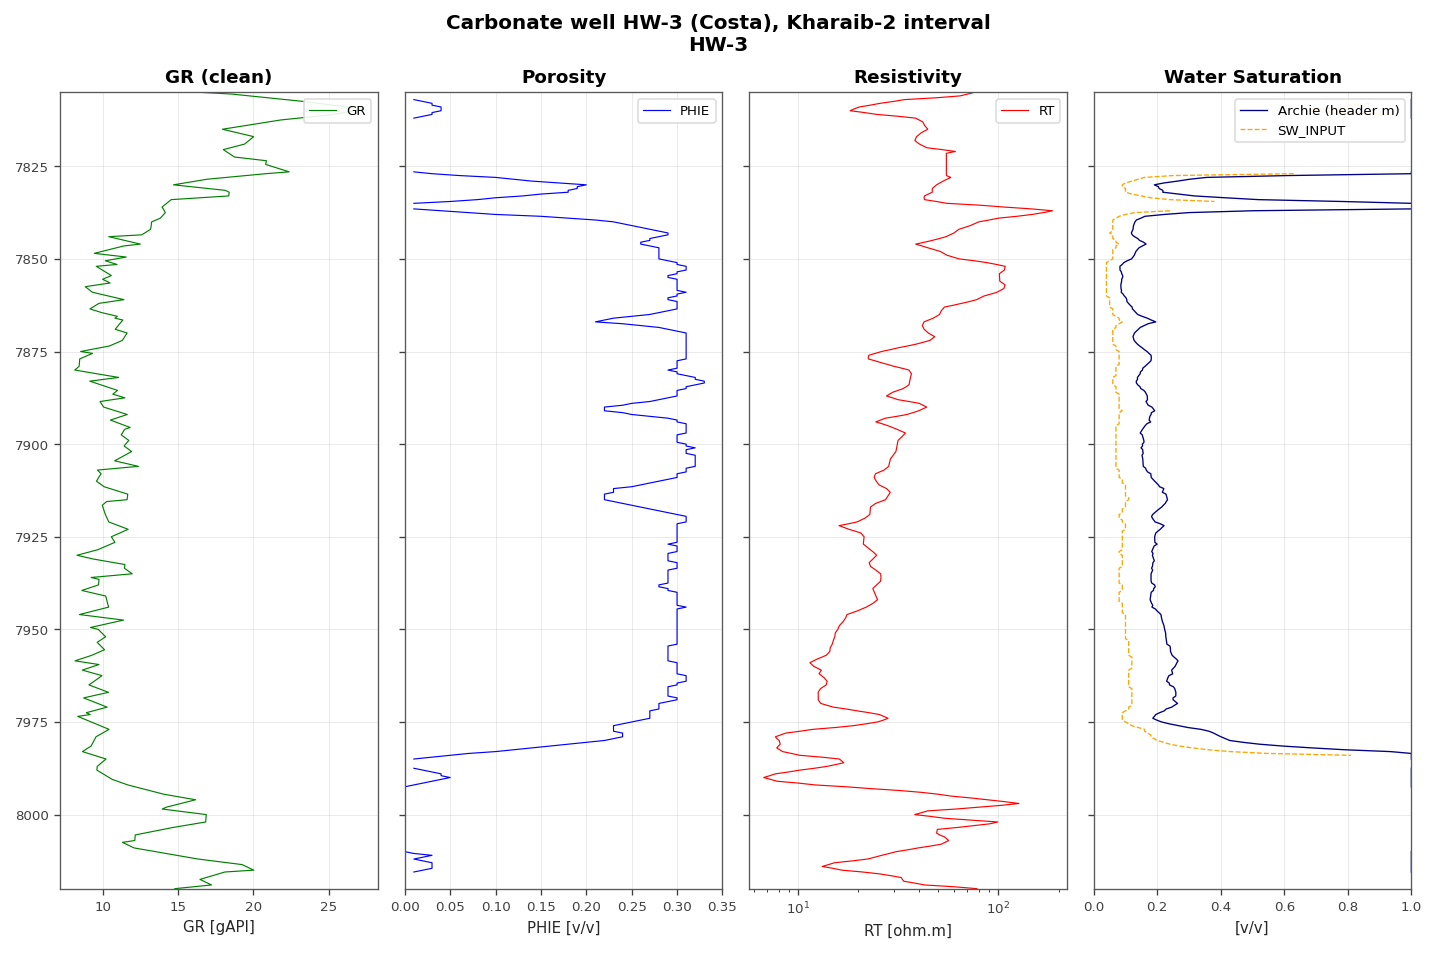

In [15]:
# Carbonate HW-3 depth overlay via the library LogPlot. Attach porosity and
# both saturation curves to the well; GR and RT are already present.
from petrophys.visualization import LogPlot

hw3.add_curve('PHIE',      phie_hw3, 'v/v', 'Core-corrected porosity')
hw3.add_curve('SW_ARCHIE', sw_hw3,   'v/v', 'Archie Sw (header m)')

lp = LogPlot(hw3, figsize=(12, 8))
lp.create_figure(n_tracks=4)

lp.add_curve(0, 'GR', color='green', linewidth=0.7)
lp.axes[0].set_title('GR (clean)')

lp.add_curve(1, 'PHIE', color='blue', linewidth=0.7, xlim=(0, 0.35))
lp.axes[1].set_title('Porosity')

lp.add_curve(2, 'RT', color='red', linewidth=0.7, log_scale=True)
lp.axes[2].set_title('Resistivity')

lp.add_curve(3, 'SW_ARCHIE', color='navy',   linewidth=0.8, xlim=(0, 1),
             label='Archie (header m)')
lp.add_curve(3, 'SW_INPUT',  color='orange', linewidth=0.8, linestyle='--',
             xlim=(0, 1), label='SW_INPUT')
lp.axes[3].set_title('Water Saturation')

lp.add_title('Carbonate well HW-3 (Costa), Kharaib-2 interval')
lp.set_depth_range()
lp.show()

### Clastic vs carbonate - which model, and why

| | Clastic (30/6-5) | Carbonate (HW-3) |
|---|---|---|
| Clay content | Variable, often high $V_{cl}$ | Very low $V_{cl}$ (clean) |
| Dominant $S_w$ problem | Clay conductivity | Complex/disconnected pore geometry |
| Model choice | Shaly-sand (Simandoux / Indonesia / regional forms) | **Archie**, but with measured $m, n$ |
| Key parameter to nail | $R_{cl}$, CEC, $R_{wb}$ | $m$ (cementation exponent), $n$ |
| Where the parameter comes from | Shale intervals, SCAL/CEC | Core / SCAL / Pickett; often in the LAS header |

The take-away: **the model is chosen by the rock, not by habit.** In clastics the
enemy is clay, so you spend your effort on shaly-sand corrections. In carbonates
the rock is clean but the pore system is wild, so you keep Archie and instead spend
your effort measuring $m$ and $n$ - which is exactly why HW-3 ships them in its
header. On the gap between our Archie result (mean 0.299) and the stored
`SW_INPUT` curve (mean 0.120): `SW_INPUT` was built with a different $R_w$/model
chain than the header parameters we used, so the comparison is a lesson in
**parameter provenance** - know which chain produced a curve before trusting or
matching it - not a scoring of either curve. And keep the $m$-sensitivity honest:
our own demo shows that moving $m$ from 2.0 to the header 2.03 shifts mean $S_w$
by only 0.004; it is a realistic carbonate $\Delta m$ of ~0.5 (say 2.0 vs 2.5 in
vuggy rock - try Exercise 3) that changes pay calls.

## Pitfalls & parameter choices

- **$R_w$ dominates everything.** A 2x error in $R_w$ moves $S_w$ by roughly
  $\sqrt{2}$. Get it from an SP-derived $R_w$, a water-zone Pickett intercept, or a
  produced-water sample - not a guess.
- **Don't use a shaly-sand model in clean rock as insurance.** It won't hurt much,
  but if $R_{cl}$/CEC are poorly known it can add noise. Route on $V_{cl}$.
- **$m$ and $n$ are not universally 2.** Carbonates and cemented sands push $m$ up;
  oil-wet rocks push $n$ up. Both raise computed $S_w$. Measure them when the
  answer matters.
- **Waxman-Smits CEC is meq/g, not meq/100g.** Divide lab values by 100. And $B$
  is temperature/salinity dependent (roughly 2-5 S/m per meq/cc at reservoir
  temperature) - a wrong $B$ silently rescales the whole clay term.
- **Dual-Water and Waxman-Smits use *total* porosity**, not effective. We built a
  proper PHIT (lesson 04's adaptive neutron-density blend) for Dual-Water;
  Waxman-Smits above still uses the nd-average as a stand-in - swap in PHIT (or a
  measured $\phi_t$) when you have it.
- **$R_{cl}$ from shale**: estimating it from the shaliest samples (as we did) is a
  reasonable field trick, but a bad shale baseline propagates straight into $S_w$.

## Recap

- **Archie** is the clean-rock baseline: $S_w^n = a R_w / (\phi^m R_t)$.
- **Shaly-sand models** (Simandoux, Indonesia, the regional North Sea and Nigeria
  forms, and - with lab data - Waxman-Smits / Dual-Water) remove
  clay conductivity and return **lower, less pessimistic** $S_w$; the
  $V_{cl}$-driven ones converge on Archie in clean rock, and all of them diverge
  in shale.
- The **spread between models** is a direct read on parameter uncertainty.
- **`calculate_sw(model='auto')`** routes sample-by-sample so a well can mix models.
- The **Pickett plot** derives $m$ (and $R_w$) from the water line's slope and
  intercept - a data-driven alternative to assuming 2.0.
- **$S_{xo}$** (flushed zone) uses Archie with $R_{xo}, R_{mf}$; $S_{xo}-S_w$ flags
  moveable hydrocarbon.
- **Carbonates** stay on Archie but demand measured $m, n$; **clastics** demand
  shaly-sand corrections. The rock picks the model.

## Try it yourself

> **Exercise 1.** Re-run the model comparison with `RW = 0.05` instead of 0.070,
> then with the header's 0.7. How much does mean Archie $S_w$ change, and does the
> spread between the shaly-sand models change too?
>
> **Exercise 2.** Take the Pickett-derived $m$ and recompute Archie $S_w$ with it.
> Compare to the $m=2.0$ result - is your pay interval bigger or smaller?
>
> **Exercise 3.** On HW-3, sweep $m$ from 1.8 to 2.6 and plot mean Archie $S_w$ vs
> $m$. This is the carbonate practitioner's core-calibration sensitivity in one
> chart.

## What's next

Continue with **08 - Permeability**, where we turn saturation and porosity into a
flow property using the Timur and Coates-Denoo estimators, and calibrate a
poro-perm transform against core data.